# Is the day's high or low set in the first X minutes?

**Hypothesis.** Stocks reveal their daily low or high early: within the
first X minutes, the day's low or the day's high is set on at least 60% of
days. X isn't fixed: the test finds the earliest X that reaches 60% (the
`60% at X` columns). The stocks in `COMPARE` are benchmarked against SPY and
QQQ in section 5, and sections 1–4 look at one `SYMBOL` in detail.

- **60% is an arbitrary benchmark** (`TARGET`), not a number from theory.
- `ENTRY_X` = 20 (09:50 ET) is a fixed reference for comparing with chance,
  by year, and for the trade.
- "Low or high" is the `either` column. A trade needs to know which one, so
  the low and the high are also tested on their own.

**Definitions**

- **Bars:** Alpaca SIP 1-minute bars, full 09:30–16:00 ET sessions only
  (early closes are dropped). Minute 0 is the 09:30 bar, and a session has
  390 of them.
- **`t_low` / `t_high`:** the minute of the first bar that touches the day's
  low or high.
- **Low set in the first X minutes** (`t_low < X`) is the same event as
  "the low of the first X minutes holds for the rest of the day."
  - You only know it at the close.
  - You can still trade it: buy at minute X with a stop under that low.

**Two baselines.** The raw rate always reaches 100% at X = 390, so it has to
be compared against chance. 390 because that's the session length, and at X =
390 the result is 100% by definition.

- **Random walk, constant volatility.** A random walk also puts its extremes
  near the open and the close. This is the arcsine law:
  P(t_low < X) ≈ (2/π)·arcsin(√(X/390)), which is about 15% at X = 20, not
  the 5% a uniform guess gives. Beating it shows the open matters.
- **Random walk, volatility-matched.** The same walk, but each minute's step
  size follows this stock's typical move for that minute. The open is the
  most volatile part of the day, which alone pushes extremes there.
  - This null has no predictability at all, so it is the one a trade has
    to beat.
  - **The edge** is observed − the vol-matched rate.
  - **The best entry X** is where that excess peaks.

**Sections**

1. Hit rate vs chance
2. When the extremes happen
3. By how much, at `ENTRY_X`
4. Stability by year
5. The stocks vs SPY and QQQ


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from utils.alpaca_bars import load_minute_bars

LOW, HIGH, MUTED = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "lines.linewidth": 2,
    "legend.frameon": False,
})

In [2]:
SYMBOL = "NVDA"
START, END = "2023-01-01", "2026-10-01"  # Pinned so reruns see the same days.
ENTRY_X = 20  # Minutes after the open, for section 3.
TARGET = 0.60  # Hypothesis benchmark hit rate. Arbitrary.
WINDOWS = [1, 5, 10, 15, 20, 30, 45, 60, 90, 120]
COMPARE = ["SPY", "QQQ", "NVDA", "TSLA", "AAPL", "GOOGL", "CRWD", "ORCL", "INTC", "PLTR"]  # SPY, QQQ: market controls.
DATA_DIR = Path("data")  # Parquet cache, committed with the repo.
SESSION = 390  # Bars in a full 09:30-16:00 session.

In [3]:
bars = load_minute_bars(SYMBOL, START, END, DATA_DIR)
print(
    f"{SYMBOL}: {len(bars):,} bars over {bars.index.normalize().nunique()} "
    f"sessions, {bars.index[0]:%Y-%m-%d} to {bars.index[-1]:%Y-%m-%d}"
)

NVDA: 363,090 bars over 931 sessions, 2023-01-03 to 2026-09-30


In [4]:
def tag(bars: pd.DataFrame) -> pd.DataFrame:
    """Add `minute` (0 = the 09:30 bar) and `date` (session) columns."""
    return bars.assign(
        minute=bars.index.hour * 60 + bars.index.minute - 570,
        date=bars.index.tz_localize(None).normalize(),
    )


def day_stats(bars: pd.DataFrame) -> pd.DataFrame:
    """One row per session: OHLC plus the minute the high and low were set.

    Ties go to the earliest bar.
    """
    b = tag(bars)
    g = b.groupby("date")
    return pd.DataFrame({
        "open": g["open"].first(),
        "high": g["high"].max(),
        "low": g["low"].min(),
        "close": g["close"].last(),
        "t_high": b.loc[g["high"].idxmax(), "minute"].to_numpy(),
        "t_low": b.loc[g["low"].idxmin(), "minute"].to_numpy(),
    })


def clock(minute: int) -> str:
    """Minute after the open -> 'HH:MM (HH:MM)', ET then PT."""
    h, m = divmod(570 + minute, 60)
    return f"{h:02d}:{m:02d} ({h - 3:02d}:{m:02d})"

In [5]:
# Check day_stats on two synthetic sessions with known extremes.
idx = pd.date_range(
    "2024-01-02 09:30", periods=SESSION, freq="min", tz="America/New_York"
)
idx = idx.append(idx + pd.Timedelta(days=1))
px = np.full(2 * SESSION, 100.0)
px[3], px[200] = 90, 110  # Day 1: low at minute 3, high at minute 200.
px[SESSION], px[-1] = 120, 80  # Day 2: high at minute 0, low at 389.
px[[10, 20]] = 90  # A tied low later on day 1 must not win.
fake = day_stats(pd.DataFrame(dict.fromkeys(["open", "high", "low", "close"], px), index=idx))
assert fake.t_low.tolist() == [3, 389], fake
assert fake.t_high.tolist() == [200, 0], fake
assert fake.low.tolist() == [90, 80] and fake.high.tolist() == [110, 120]
print("day_stats OK")

day_stats OK


## 1. Hit rate vs chance

For every window X (1 to 390 minutes): the share of days whose low or high
was set in the first X minutes.
- **Gray lines:** the same rates for the two random walks (dashed: constant
  volatility; dotted: vol-matched).
- **Right panel:** the excess over the vol-matched walk. The gray band is
  ±2 standard errors of noise for this many days.
- **`z`:** the excess in standard errors.
  - The peak is picked from 390 windows, so it can reach z ≈ 3 on pure noise
    (this notebook's synthetic no-edge test did).
  - Trust an X only if it was chosen in advance, or if it holds every year
    (section 4) and doesn't also show up in SPY/QQQ (section 5).
- **Table:** also covers "either", meaning the low or the high.

In [6]:
X = np.arange(1, SESSION + 1)  # Window lengths, minutes.


def hit_curve(t) -> np.ndarray:
    """Share of days with t < x, for every window x in X."""
    t = np.sort(np.asarray(t))
    return np.searchsorted(t, X, side="left") / len(t)


def curves(t_low, t_high) -> pd.DataFrame:
    """Hit-rate curves for the low, the high, and either one."""
    t_low, t_high = np.asarray(t_low), np.asarray(t_high)
    return pd.DataFrame(
        {
            "low": hit_curve(t_low),
            "high": hit_curve(t_high),
            "either": hit_curve(np.minimum(t_low, t_high)),
        },
        index=pd.Index(X, name="X"),
    )


def null_curves(profile=None, n: int = 20_000) -> pd.DataFrame:
    """Hit-rate curves of n random walks over one session.

    Each minute's step size follows `profile` (constant if None). Point 0
    is the open and point j > 0 closes bar j - 1, so an extreme at point j
    is in bar max(j - 1, 0).
    """
    steps = np.random.default_rng(0).standard_normal((n, SESSION))
    if profile is not None:
        steps *= profile
    walks = np.hstack([np.zeros((n, 1)), steps.cumsum(axis=1)])
    return curves(
        np.maximum(walks.argmin(axis=1) - 1, 0),
        np.maximum(walks.argmax(axis=1) - 1, 0),
    )


def vol_profile(bars: pd.DataFrame) -> np.ndarray:
    """Typical size of each minute's move, with every day scaled to unit vol."""
    b = tag(bars)
    r = np.log(b.close).groupby(b.date).diff()
    r = r.fillna(np.log(b.close / b.open))  # Minute 0: skip the overnight gap.
    r /= r.groupby(b.date).transform("std")
    by_minute = r.groupby(b.minute).std().reindex(range(SESSION))
    return by_minute.interpolate(limit_direction="both").to_numpy()


RW = null_curves()  # Constant volatility; the same for every symbol.
arcsine = 2 / np.pi * np.arcsin(np.sqrt(20 / SESSION))
print(
    f"Random walk P(low in first 20 min): simulated {RW.low[20]:.1%}, "
    f"arcsine law {arcsine:.1%}"
)

days = day_stats(bars)
obs = curves(days.t_low, days.t_high)
VM = null_curves(vol_profile(bars))  # Vol-matched to this symbol.
excess = obs - VM


def null_se(vm: pd.DataFrame, n: int) -> pd.DataFrame:
    """Standard error of an n-day hit rate if the vol-matched null is true."""
    return np.sqrt(vm * (1 - vm) / n)


z = excess / null_se(VM, len(days))

Random walk P(low in first 20 min): simulated 14.4%, arcsine law 14.5%


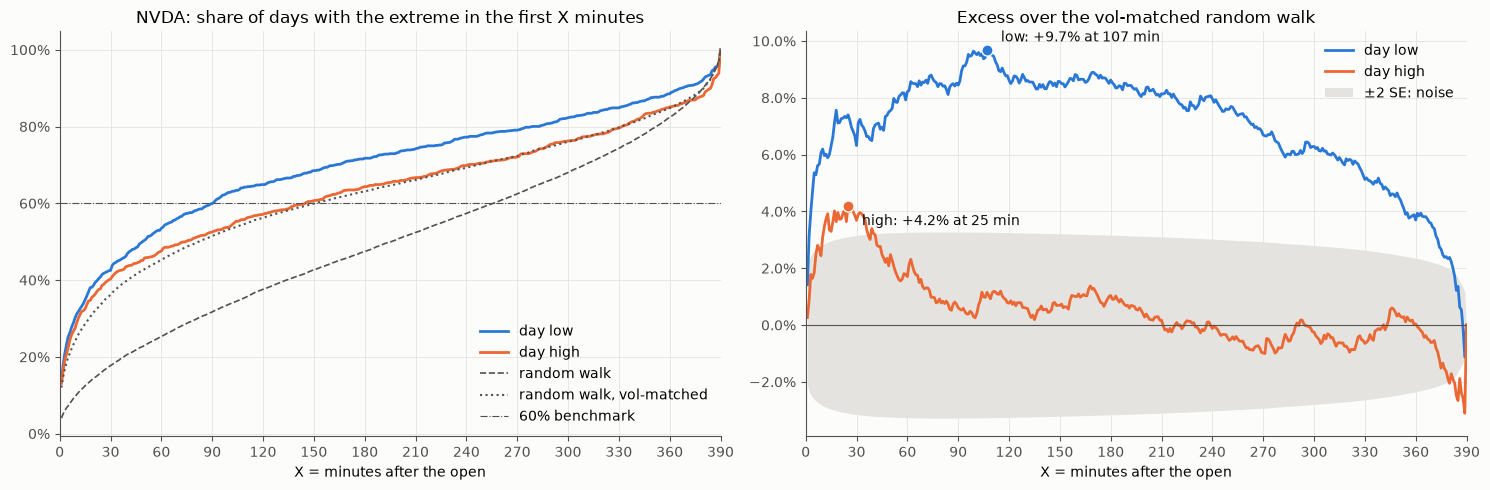

In [7]:
fig, (a, b) = plt.subplots(1, 2, figsize=(15, 5))
for side, color, dy in [("low", LOW, 6), ("high", HIGH, -14)]:
    a.plot(X, obs[side], color=color, label=f"day {side}")
    b.plot(X, excess[side], color=color, label=f"day {side}")
    peak = excess[side].idxmax()
    b.plot(peak, excess[side][peak], "o", color=color, ms=8, mec="#fcfcfb")
    b.annotate(
        f"{side}: {excess[side][peak]:+.1%} at {peak} min",
        (peak, excess[side][peak]),
        xytext=(10 if peak < 270 else -10, dy),
        textcoords="offset points",
        ha="left" if peak < 270 else "right",
        color="#0b0b0b",
    )
a.plot(X, RW.low, "--", color=MUTED, lw=1.2, label="random walk")
a.plot(X, VM.low, ":", color=MUTED, lw=1.5, label="random walk, vol-matched")
a.axhline(TARGET, color=MUTED, lw=0.8, ls="-.", label=f"{TARGET:.0%} benchmark")
a.set_title(f"{SYMBOL}: share of days with the extreme in the first X minutes")
se2 = 2 * null_se(VM, len(days)).low
b.fill_between(X, -se2, se2, color="#e4e3df", lw=0, label="±2 SE: noise")
b.set_title("Excess over the vol-matched random walk")
b.axhline(0, color=MUTED, lw=0.8)
for ax in (a, b):
    ax.set_xlabel("X = minutes after the open")
    ax.set_xlim(0, SESSION)
    ax.set_xticks(range(0, SESSION + 1, 30))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend(loc="lower right" if ax is a else "upper right")
plt.tight_layout()
plt.show()

In [8]:
def summary(obs: pd.DataFrame, vm: pd.DataFrame, n: int, windows=WINDOWS):
    """Observed rate, both nulls, and the excess over the vol-matched one."""
    se = null_se(vm, n)
    parts = {}
    for side in obs.columns:
        o, v = obs[side].loc[windows], vm[side].loc[windows]
        parts[side] = pd.DataFrame({
            "P": o,
            "random walk": RW[side].loc[windows],
            "vol-matched": v,
            "excess": o - v,
            "z": (o - v) / se[side].loc[windows],
        })
    return pd.concat(parts, axis=1)


def first_x(curve: pd.Series, p: float):
    """Smallest window whose hit rate reaches p."""
    hit = curve.index[curve >= p]
    return hit[0] if len(hit) else None


table = summary(obs, VM, len(days))
display(table.style.format(
    {c: "{:+.1f}" if c[1] == "z" else "{:.1%}" for c in table.columns}
))
for side in obs.columns:
    peak = excess[side].idxmax()
    print(
        f"{side:>6}: peak excess {excess[side][peak]:+.1%} "
        f"(z = {z[side][peak]:+.1f}) at X={peak} min "
        f"(window ends {clock(peak)}): P={obs[side][peak]:.1%} vs "
        f"{VM[side][peak]:.1%} vol-matched, {RW[side][peak]:.1%} random walk. "
        f"Reaches {TARGET:.0%} at X={first_x(obs[side], TARGET)}, "
        f"vol-matched at X={first_x(VM[side], TARGET)}."
    )

   low: peak excess +9.7% (z = +5.9) at X=107 min (window ends 11:17 (08:17)): P=64.0% vs 54.3% vol-matched, 35.0% random walk. Reaches 60% at X=91, vol-matched at X=151.
  high: peak excess +4.2% (z = +2.7) at X=25 min (window ends 09:55 (06:55)): P=38.7% vs 34.5% vol-matched, 16.7% random walk. Reaches 60% at X=145, vol-matched at X=151.
either: peak excess +10.1% (z = +6.3) at X=17 min (window ends 09:47 (06:47)): P=70.0% vs 59.9% vol-matched, 27.2% random walk. Reaches 60% at X=11, vol-matched at X=18.


## 2. When the extremes happen

The share of days whose low (top) or high (bottom) fell in each 5-minute
bucket. The gray lines are the two random walks: dashed is constant
volatility, solid is vol-matched. Times are ET, with PT in parentheses.

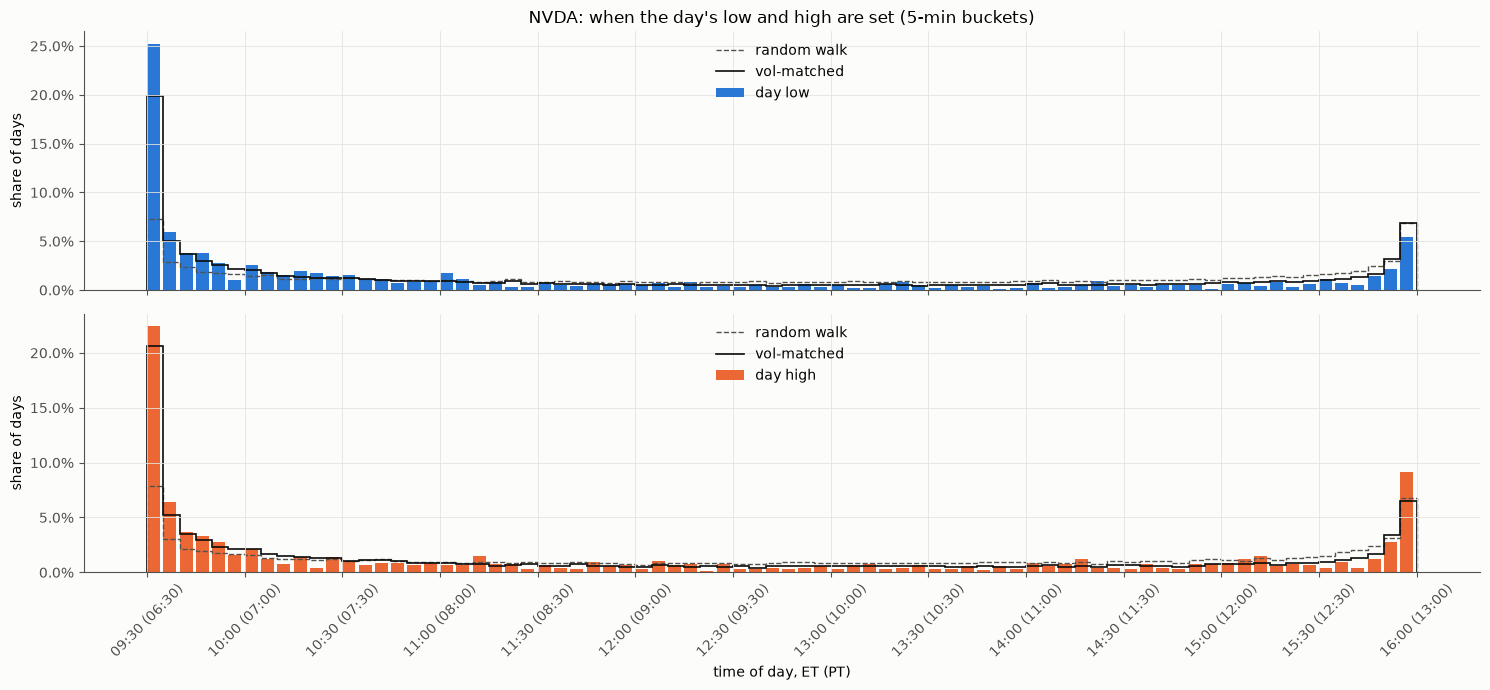

In [9]:
bins = np.arange(0, SESSION + 1, 5)


def bucket_mass(curve: pd.Series) -> np.ndarray:
    """Probability per bucket from a hit-rate curve (curve[x] = P(t < x))."""
    cdf = np.r_[0, curve.to_numpy()]
    return cdf[bins[1:]] - cdf[bins[:-1]]


fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
for ax, side, color in zip(axes, ["low", "high"], [LOW, HIGH]):
    share = np.histogram(days[f"t_{side}"], bins)[0] / len(days)
    ax.bar(bins[:-1], share, width=4, align="edge", color=color, label=f"day {side}")
    ax.stairs(bucket_mass(RW[side]), bins, color=MUTED, ls="--", lw=1, label="random walk")
    ax.stairs(bucket_mass(VM[side]), bins, color="#0b0b0b", lw=1.2, label="vol-matched")
    ax.set_ylabel("share of days")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend(loc="upper center")
ticks = range(0, SESSION + 1, 30)
axes[1].set_xticks(ticks, [clock(t) for t in ticks], rotation=45)
axes[1].set_xlabel("time of day, ET (PT)")
axes[0].set_title(f"{SYMBOL}: when the day's low and high are set (5-min buckets)")
plt.tight_layout()
plt.show()

## 3. By how much, entering at minute `ENTRY_X`

**The trade**
- **Long:** at the close of minute X−1, buy, with a stop just under the low
  of the first X minutes, and exit at the close.
- **Short:** the mirror, with the stop over the first-X high.

**How to read the tables**
- Days are split by whether the first-X extreme held. **That split uses
  hindsight:** at entry you can't know which group you're in.
- The `all days` rows and the stop-rule P&L are what the trade would
  actually have made.
- **No costs, and stops fill at the stop price.**

In [10]:
def entry_outcomes(bars: pd.DataFrame, x: int) -> pd.DataFrame:
    """Per session: the first-x extremes, the entry price, what came after."""
    b = tag(bars)
    first = b[b.minute < x].groupby("date").agg(
        low_x=("low", "min"), high_x=("high", "max"), entry=("close", "last")
    )
    rest = b[b.minute >= x].groupby("date").agg(
        low_after=("low", "min"), high_after=("high", "max"),
        close=("close", "last"),
    )
    return first.join(rest, how="inner")


def sides(bars: pd.DataFrame, x: int) -> dict:
    """Long and short outcomes for an entry at minute x, and which days held."""
    o = entry_outcomes(bars, x)
    rng_x = (o.high_x - o.low_x).replace(0, np.nan)
    held_low = o.low_after >= o.low_x
    held_high = o.high_after <= o.high_x
    long_side = pd.DataFrame({
        "stop distance": o.entry / o.low_x - 1,
        "run-up to later high": o.high_after / o.entry - 1,
        "entry to close": o.close / o.entry - 1,
        "undercut of first-X low": ((o.low_x - o.low_after) / o.low_x).where(~held_low),
        "undercut / first-X range": ((o.low_x - o.low_after) / rng_x).where(~held_low),
        "stop-rule P&L": np.where(held_low, o.close / o.entry - 1, o.low_x / o.entry - 1),
    })
    short_side = pd.DataFrame({
        "stop distance": o.high_x / o.entry - 1,
        "run-down to later low": 1 - o.low_after / o.entry,
        "entry to close": 1 - o.close / o.entry,
        "overshoot of first-X high": ((o.high_after - o.high_x) / o.high_x).where(~held_high),
        "overshoot / first-X range": ((o.high_after - o.high_x) / rng_x).where(~held_high),
        "stop-rule P&L": np.where(held_high, 1 - o.close / o.entry, 1 - o.high_x / o.entry),
    })
    return {"long": (long_side, held_low), "short": (short_side, held_high)}


def outcome_table(df: pd.DataFrame, held: pd.Series) -> pd.DataFrame:
    """Mean and percentiles of each outcome: held days, broken days, all."""
    groups = {
        f"held ({held.mean():.0%} of days)": df[held],
        f"broke ({1 - held.mean():.0%})": df[~held],
        "all days": df,
    }
    stats = ["mean", "25%", "50%", "75%", "90%"]
    return pd.concat({
        name: g.describe(percentiles=[.25, .5, .75, .9]).loc[stats]
        for name, g in groups.items()
    })


trades = sides(bars, ENTRY_X)
# Same event, computed two ways: the first-X low held <=> t_low < X.
assert trades["long"][1].eq(days.t_low.loc[trades["long"][1].index] < ENTRY_X).all()
assert trades["short"][1].eq(days.t_high.loc[trades["short"][1].index] < ENTRY_X).all()

for name, (df, held) in trades.items():
    extreme = "low" if name == "long" else "high"
    pnl = df["stop-rule P&L"]
    t = pnl.mean() / pnl.std() * np.sqrt(len(pnl))
    print(
        f"{name.upper()} at minute {ENTRY_X} ({clock(ENTRY_X)}): first-{ENTRY_X} "
        f"{extreme} held on {held.mean():.1%} of {len(df)} days.\n"
        f"  stop rule: mean {pnl.mean():+.3%}/day, median {pnl.median():+.3%}, "
        f"win rate {(pnl > 0).mean():.1%}, t = {t:.2f}\n"
        f"  no stop, hold to close: mean {df['entry to close'].mean():+.3%}/day"
    )
    display(outcome_table(df, held).style.format(
        {c: "{:.2f}x" if "range" in c else "{:.2%}" for c in df.columns},
        na_rep="",
    ))

LONG at minute 20 (09:50 (06:50)): first-20 low held on 38.7% of 931 days.
  stop rule: mean +0.112%/day, median -0.228%, win rate 32.2%, t = 2.34
  no stop, hold to close: mean +0.074%/day


SHORT at minute 20 (09:50 (06:50)): first-20 high held on 35.9% of 931 days.
  stop rule: mean +0.036%/day, median -0.265%, win rate 27.9%, t = 0.77
  no stop, hold to close: mean -0.074%/day


## 4. Stability by year

If the effect is real it should show up every year, not just in one
regime.

In [11]:
XS = sorted({10, ENTRY_X, 30, 60})
SIDES = ("low", "high", "either")
t_side = {
    "low": days.t_low,
    "high": days.t_high,
    "either": np.minimum(days.t_low, days.t_high),
}
COLS = [(side, f"first {x}m") for side in SIDES for x in XS]
year = days.index.year.rename("year")
stability = pd.DataFrame(
    {(side, f"first {x}m"): (t_side[side] < x).groupby(year).mean()
     for side in SIDES for x in XS}
)
stability.loc["vol-matched"] = [VM[side][x] for side in SIDES for x in XS]
stability.loc["random walk"] = [RW[side][x] for side in SIDES for x in XS]
stability[("", "days")] = days.groupby(year).size()
display(stability.style.format("{:.1%}", subset=COLS).format(
    "{:.0f}", subset=[("", "days")], na_rep=""
))

## 5. The stocks vs SPY and QQQ

The same tests for every symbol in `COMPARE`, at X = `ENTRY_X`.
- **SPY and QQQ** are the benchmarks. They track the whole market, so if the
  stocks look like them, the pattern belongs to the market, not to single
  stocks.
- **Stocks (avg)** averages the hit-rate curves of the non-index symbols. Its
  trade row is an equal-weight portfolio of them, one position each per day.
- The excess is over each symbol's own vol-matched walk.
- `60% at X` is the hypothesis's X: the first window where the rate reaches
  `TARGET`.

In [12]:
MARKET = ["SPY", "QQQ"]  # Benchmarks: index funds, no single company.
STOCKS = [s for s in COMPARE if s not in MARKET]
AVG = "stocks (avg)"


def symbol_results(sym: str) -> dict:
    """Days, hit-rate curves, chance curves and trades for one symbol."""
    sym_bars = load_minute_bars(sym, START, END, DATA_DIR)
    d = day_stats(sym_bars)
    return {
        "days": d,
        "obs": curves(d.t_low, d.t_high),
        "vm": null_curves(vol_profile(sym_bars)),
        "trade": sides(sym_bars, ENTRY_X),
    }


res = {sym: symbol_results(sym) for sym in COMPARE}
avg_obs = sum(res[s]["obs"] for s in STOCKS) / len(STOCKS)
avg_vm = sum(res[s]["vm"] for s in STOCKS) / len(STOCKS)
ORDER = STOCKS + [AVG] + MARKET

In [13]:
def rate_row(obs: pd.DataFrame, vm: pd.DataFrame, n=None) -> dict:
    """Rates at ENTRY_X for each side, and when each reaches TARGET."""
    row = {}
    for side in SIDES:
        o, v = obs[side][ENTRY_X], vm[side][ENTRY_X]
        row[(side, "P")] = o
        row[(side, "chance")] = v
        row[(side, "excess")] = o - v
        # Reason: no z for the average; the stocks share the same days.
        row[(side, "z")] = (o - v) / np.sqrt(v * (1 - v) / n) if n else np.nan
        row[(side, f"{TARGET:.0%} at X")] = first_x(obs[side], TARGET)
        row[(side, f"chance {TARGET:.0%} at X")] = first_x(vm[side], TARGET)
    return row


rows = {s: rate_row(r["obs"], r["vm"], len(r["days"])) for s, r in res.items()}
rows[AVG] = rate_row(avg_obs, avg_vm)
rates = pd.DataFrame.from_dict(rows, orient="index").loc[ORDER]
rates.columns = pd.MultiIndex.from_tuples(rates.columns)
display(rates.style.format(
    {c: "{:+.1f}" if c[1] == "z" else "{:.0f}" if "at X" in c[1] else "{:.1%}"
     for c in rates.columns},
    na_rep="",
))
for side in SIDES:
    s = rates.loc[STOCKS, side]
    print(
        f"{side:>6}: {(s['P'] >= TARGET).sum()}/{len(STOCKS)} stocks at or "
        f"above {TARGET:.0%} by minute {ENTRY_X}, {(s['z'] > 2).sum()} beat "
        f"chance with z > 2. {AVG} {rates.loc[AVG, (side, 'P')]:.1%}, "
        + ", ".join(f"{m} {rates.loc[m, (side, 'P')]:.1%}" for m in MARKET)
    )
    fastest = s[f"{TARGET:.0%} at X"].sort_values().head(4)
    print(f"        first to {TARGET:.0%}: " + ", ".join(
        f"{sym} {x:.0f} min" for sym, x in fastest.items()))

   low: 0/8 stocks at or above 60% by minute 20, 8 beat chance with z > 2. stocks (avg) 39.8%, SPY 24.1%, QQQ 28.2%
        first to 60%: CRWD 65 min, PLTR 81 min, GOOGL 85 min, NVDA 91 min
  high: 0/8 stocks at or above 60% by minute 20, 6 beat chance with z > 2. stocks (avg) 37.4%, SPY 20.8%, QQQ 25.8%
        first to 60%: TSLA 107 min, PLTR 108 min, INTC 113 min, CRWD 122 min
either: 8/8 stocks at or above 60% by minute 20, 8 beat chance with z > 2. stocks (avg) 74.4%, SPY 44.9%, QQQ 54.0%
        first to 60%: CRWD 7 min, GOOGL 8 min, INTC 9 min, PLTR 9 min


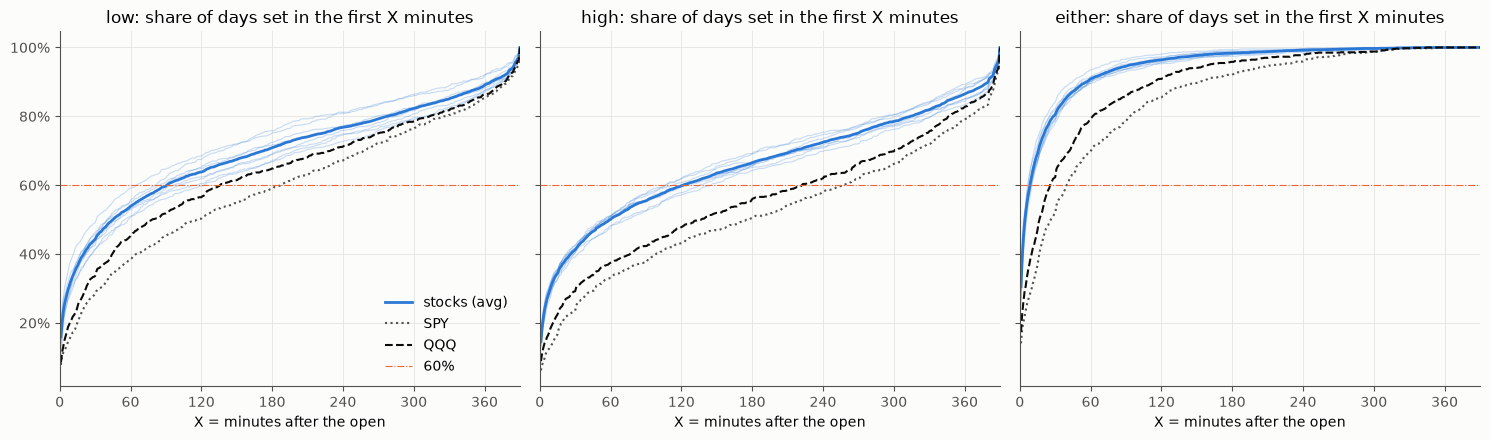

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, side in zip(axes, SIDES):
    for s in STOCKS:
        ax.plot(X, res[s]["obs"][side], color=LOW, lw=0.8, alpha=0.25)
    ax.plot(X, avg_obs[side], color=LOW, label=AVG)
    for m, ls, color in zip(MARKET, [":", "--"], [MUTED, "#0b0b0b"]):
        ax.plot(X, res[m]["obs"][side], ls=ls, color=color, lw=1.5, label=m)
    ax.axhline(TARGET, color=HIGH, lw=0.8, ls="-.", label=f"{TARGET:.0%}")
    ax.set_title(f"{side}: share of days set in the first X minutes")
    ax.set_xlabel("X = minutes after the open")
    ax.set_xlim(0, SESSION)
    ax.set_xticks(range(0, SESSION + 1, 60))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

In [15]:
def extreme_times(d: pd.DataFrame) -> dict:
    """Minute the low, the high, and the first of the two were set."""
    return {
        "low": d.t_low,
        "high": d.t_high,
        "either": np.minimum(d.t_low, d.t_high),
    }


def yearly(d: pd.DataFrame, side: str) -> pd.Series:
    """Share of days per year with the extreme set before ENTRY_X."""
    hit = extreme_times(d)[side] < ENTRY_X
    return hit.groupby(d.index.year.rename("year")).mean()


by_year = pd.concat({
    side: pd.DataFrame({s: yearly(r["days"], side) for s, r in res.items()})
    for side in SIDES
})
chance_x = pd.DataFrame({s: r["vm"].loc[ENTRY_X] for s, r in res.items()})
st = by_year[STOCKS]
st_chance = chance_x.loc[st.index.get_level_values(0), STOCKS].to_numpy()
by_year[AVG] = st.mean(axis=1)
by_year[f"stocks >= {TARGET:.0%}"] = (st >= TARGET).sum(axis=1)
by_year["stocks > chance"] = (st.to_numpy() > st_chance).sum(axis=1)
by_year = by_year[[AVG] + MARKET + STOCKS + list(by_year.columns[-2:])]
display(by_year.style.format("{:.1%}", subset=[AVG] + MARKET + STOCKS))

In [16]:
def trade_row(trade: dict) -> dict:
    """Mean, t, win rate and no-stop mean of the entries at ENTRY_X."""
    row = {}
    for name, (df, _) in trade.items():
        pnl = df["stop-rule P&L"]
        row[(name, "mean")] = pnl.mean()
        row[(name, "t")] = pnl.mean() / pnl.std() * np.sqrt(len(pnl))
        row[(name, "win rate")] = (pnl > 0).mean()
        row[(name, "no stop")] = df["entry to close"].mean()
    return row


rows = {s: trade_row(r["trade"]) for s, r in res.items()}
# Equal-weight portfolio: each day, the average of the stocks' trades.
rows[AVG] = trade_row({
    name: (
        pd.concat(
            {s: res[s]["trade"][name][0] for s in STOCKS}, axis=1
        ).T.groupby(level=1).mean().T,
        None,
    )
    for name in ("long", "short")
})
trade_stats = pd.DataFrame.from_dict(rows, orient="index").loc[ORDER]
trade_stats.columns = pd.MultiIndex.from_tuples(trade_stats.columns)
display(trade_stats.style.format(
    {c: "{:+.2f}" if c[1] == "t" else "{:.1%}" if c[1] == "win rate"
     else "{:+.3%}" for c in trade_stats.columns}
))

## Caveats

- **No costs.** The stop-rule P&L ignores spread, fees and stop slippage.
  1-minute bars also can't tell whether price hit the stop before or after a
  later move within the same bar.
- **Multiple comparisons.** Picking the best X and the best symbol from these
  tables is a search, and the winner is overstated. Before trusting an X,
  pre-register it and confirm it on data after `END`.
- **Unconditional rates.** Nothing known at the open is used yet. The obvious
  next test is to split by the opening gap (open vs the prior close):
  - Gap-down days may set the low early.
  - Gap-up days may set the high early.
- **The vol-matched profile** is estimated from the same days it is tested
  on. It only shapes step sizes, not direction, so it can't create an edge,
  but it does absorb any effect that comes purely from volatility timing.
- **Early closes are excluded,** about 3 sessions a year.